=== BẢNG THỐNG KÊ MEDIAN ROI THEO THỂ LOẠI (ĐÃ CHUẨN HÓA) ===


,genres_list,ROI
0,Documentary,2.316722
1,Music,2.120667
2,Horror,1.886369
3,Animation,1.787321
4,Family,1.543293
5,Adventure,1.388725
6,Romance,1.378736
7,Comedy,1.303358
8,Science Fiction,1.260046
9,Fantasy,1.226816


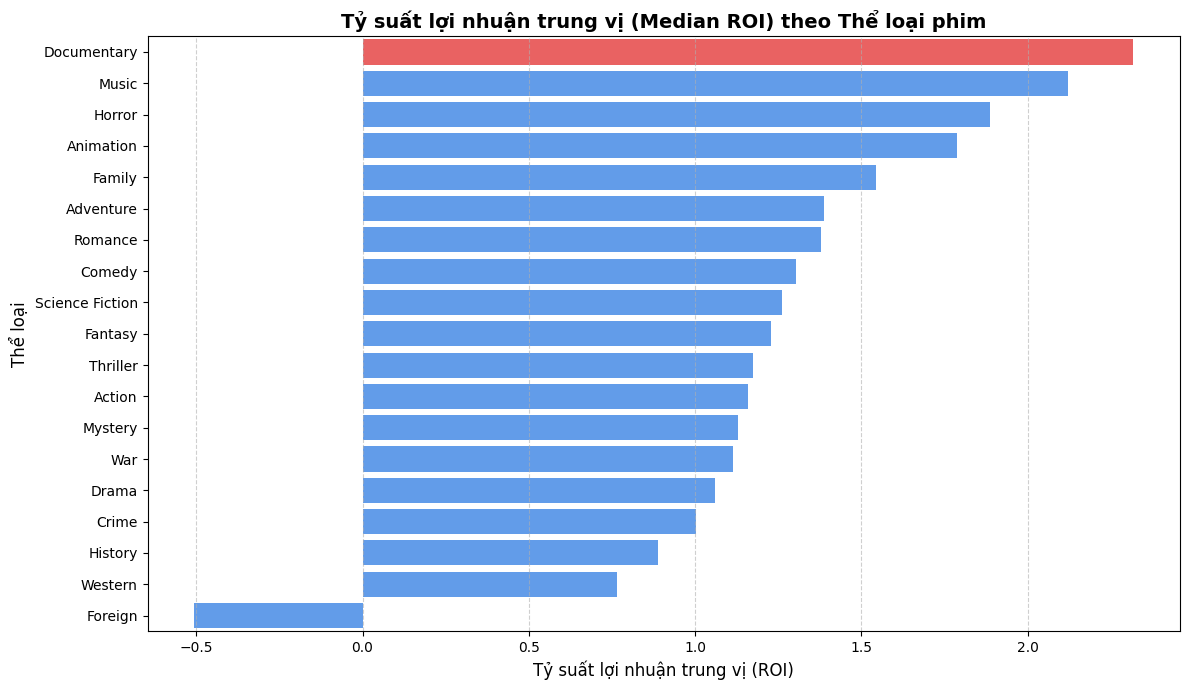

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Nạp dữ liệu từ file mới đã được làm sạch của bạn
df_movies = pd.read_csv('/content/drive/MyDrive/movies.csv')

# Lọc các dòng có doanh thu và ngân sách hợp lệ (> 0)
df_roi = df_movies[(df_movies['budget'] > 0) & (df_movies['revenue'] > 0)].copy()
df_roi['ROI'] = (df_roi['revenue'] - df_roi['budget']) / df_roi['budget']

# 2. Phân tách danh sách thể loại
# Vì bạn đã chuyển các cụm từ ghép thành 'Science_Fiction', ta chỉ cần split theo khoảng trắng bình thường
def parse_genres(genres_str):
    if pd.isna(genres_str):
        return []
    raw_genres = str(genres_str).split()
    # Khôi phục dấu cách cho định dạng hiển thị trên biểu đồ (ví dụ: Science_Fiction -> Science Fiction)
    return [g.replace('_', ' ') for g in raw_genres]

df_roi['genres_list'] = df_roi['genres'].apply(parse_genres)
df_exploded = df_roi.explode('genres_list')

# 3. Tính toán Median ROI theo từng thể loại
genre_roi = df_exploded.groupby('genres_list')['ROI'].median().reset_index()
genre_roi = genre_roi.sort_values(by='ROI', ascending=False).reset_index(drop=True)

# Hiển thị bảng dữ liệu
print("=== BẢNG THỐNG KÊ MEDIAN ROI THEO THỂ LOẠI (ĐÃ CHUẨN HÓA) ===")
display(genre_roi)

# 4. Vẽ biểu đồ
plt.figure(figsize=(12, 7))
max_roi_genre = genre_roi.iloc[0]['genres_list']
colors = ['#FF4C4C' if g == max_roi_genre else '#4C99FF' for g in genre_roi['genres_list']]

sns.barplot(
    x='ROI',
    y='genres_list',
    data=genre_roi,
    palette=colors,
    hue='genres_list',
    legend=False
)

plt.title('Tỷ suất lợi nhuận trung vị (Median ROI) theo Thể loại phim', fontsize=14, fontweight='bold')
plt.xlabel('Tỷ suất lợi nhuận trung vị (ROI)', fontsize=12)
plt.ylabel('Thể loại', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [6]:
import pandas as pd

# 1. Nạp dữ liệu gốc từ Drive
df = pd.read_csv('/content/drive/MyDrive/movies.csv')

# 2. Loại bỏ các dòng trùng lặp và các giá trị bị thiếu (nếu cần)
df_clean = df.drop_duplicates().copy()

# Loại bỏ các giá trị vô nghĩa (ví dụ: budget hoặc revenue nhỏ hơn hoặc bằng 0)
df_clean = df_clean[(df_clean['budget'] > 0) & (df_clean['revenue'] > 0)]

# 3. Định dạng lại cột ngày tháng về kiểu YYYY-MM-DD
if 'release_date' in df_clean.columns:
    df_clean['release_date'] = pd.to_datetime(df_clean['release_date'], errors='coerce').dt.strftime('%Y-%m-%d')

# 4. Xuất file movies_clean.csv trực tiếp vào thư mục MyDrive trên Google Drive
df_clean.to_csv('/content/drive/MyDrive/movies_clean.csv', index=False)
print("Đã lưu tệp movies_clean.csv thành công vào Google Drive của bạn!")


=== BẢNG DỮ LIỆU ĐÃ LÀM SẠCH VÀ CHUẨN HÓA (KHÔNG VẼ BIỂU ĐỒ) ===


,index,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,...,runtime,spoken_languages,status,tagline,title,vote_average,vote_count,cast,crew,director
0,0,237000000,Action Adventure Fantasy Science_Fiction,http://www.avatarmovie.com/,19995,culture clash future space war space colony so...,en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,...,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800,Sam Worthington Zoe Saldana Sigourney Weaver S...,"[{'name': 'Stephen E. Rivkin', 'gender': 0, 'd...",James Cameron
1,1,300000000,Adventure Fantasy Action,http://disney.go.com/disneypictures/pirates/,285,ocean drug abuse exotic island east india trad...,en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,...,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500,Johnny Depp Orlando Bloom Keira Knightley Stel...,"[{'name': 'Dariusz Wolski', 'gender': 2, 'depa...",Gore Verbinski
2,2,245000000,Action Adventure Crime,http://www.sonypictures.com/movies/spectre/,206647,spy based on novel secret agent sequel mi6,en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,...,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466,Daniel Craig Christoph Waltz L\u00e9a Seydoux ...,"[{'name': 'Thomas Newman', 'gender': 2, 'depar...",Sam Mendes
3,3,250000000,Action Crime Drama Thriller,http://www.thedarkknightrises.com/,49026,dc comics crime fighter terrorist secret ident...,en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,...,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106,Christian Bale Michael Caine Gary Oldman Anne ...,"[{'name': 'Hans Zimmer', 'gender': 2, 'departm...",Christopher Nolan
4,4,260000000,Action Adventure Science_Fiction,http://movies.disney.com/john-carter,49529,based on novel mars medallion space travel pri...,en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,...,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124,Taylor Kitsch Lynn Collins Samantha Morton Wil...,"[{'name': 'Andrew Stanton', 'gender': 2, 'depa...",Andrew Stanton
5,5,258000000,Fantasy Action Adventure,http://www.sonypictures.com/movies/spider-man3/,559,dual identity amnesia sandstorm love of one's ...,en,Spider-Man 3,The seemingly invincible Spider-Man goes up ag...,115.699814,...,139.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,The battle within.,Spider-Man 3,5.9,3576,Tobey Maguire Kirsten Dunst James Franco Thoma...,"[{'name': 'Francine Maisler', 'gender': 1, 'de...",Sam Raimi
6,6,260000000,Animation Family,http://disney.go.com/disneypictures/tangled/,38757,hostage magic horse fairy tale musical,en,Tangled,When the kingdom's most wanted-and most charmi...,48.681969,...,100.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,They're taking adventure to new lengths.,Tangled,7.4,3330,Zachary Levi Mandy Moore Donna Murphy Ron Perl...,"[{'name': 'John Lasseter', 'gender': 2, 'depar...",Byron Howard
7,7,280000000,Action Adventure Science_Fiction,http://marvel.com/movies/movie/193/avengers_ag...,99861,marvel comic sequel superhero based on comic b...,en,Avengers: Age of Ultron,When Tony Stark tries to jumpstart a dormant p...,134.279229,...,141.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,A New Age Has Come.,Avengers: Age of Ultron,7.3,6767,Robert Downey Jr. Chris Hemsworth Mark Ruffalo...,"[{'name': 'Danny Elfman', 'gender': 2, 'depart...",Joss Whedon
8,8,250000000,Adventure Fantasy Family,http://harrypotter.warnerbros.com/harrypottera...,767,witch magic broom

In [9]:
# Xuất file movies_clean.csv trực tiếp vào thư mục MyDrive trên Google Drive
df_clean.to_csv('/content/drive/MyDrive/movies_clean.csv', index=False)
print("Đã lưu tệp movies_clean.csv thành công vào Google Drive của bạn!")

Đã lưu tệp movies_clean.csv thành công vào Google Drive của bạn!


In [11]:
import pandas as pd
import numpy as np

# Tải dữ liệu
df_movies = pd.read_csv('/content/drive/MyDrive/movies.csv')

# Lọc dữ liệu hợp lệ (budget > 0 và revenue > 0)
df_valid = df_movies[(df_movies['budget'] > 0) & (df_movies['revenue'] > 0)].copy()

# 1. Phân tích Xu hướng 1: Mối quan hệ giữa Ngân sách (Budget) và Doanh thu (Revenue)
correlation = df_valid['budget'].corr(df_valid['revenue'])
print(f"1. Hệ số tương quan giữa Ngân sách và Doanh thu: {correlation:.2f}")

# 2. Phân tích Xu hướng 2: Điểm đánh giá trung bình (vote_average) theo Ngân sách
# Chia ngân sách thành các nhóm: Thấp (<10M), Trung bình (10M-50M), Cao (50M-150M), Siêu bom tấn (>150M)
bins = [0, 10e6, 50e6, 150e6, np.inf]
labels = ['Thấp (<10M)', 'Trung bình (10M-50M)', 'Cao (50M-150M)', 'Siêu bom tấn (>150M)']
df_valid['budget_group'] = pd.cut(df_valid['budget'], bins=bins, labels=labels)
budget_perf = df_valid.groupby('budget_group', observed=False).agg(
    mean_revenue=('revenue', 'mean'),
    mean_score=('vote_average', 'mean'),
    count=('index', 'count')
).reset_index()

print("\n2. Hiệu quả doanh thu và điểm số theo nhóm ngân sách:")
display(budget_perf)

# 3. Phân tích Xu hướng 3: Tháng phát hành phổ biến và doanh thu trung bình
if 'release_date' in df_valid.columns:
    df_valid['release_date'] = pd.to_datetime(df_valid['release_date'], errors='coerce')
    df_valid['release_month'] = df_valid['release_date'].dt.month
    month_perf = df_valid.groupby('release_month').agg(
        movie_count=('index', 'count'),
        avg_revenue=('revenue', 'mean')
    ).sort_values(by='avg_revenue', ascending=False)

    print("\n3. Top các tháng phát hành mang lại doanh thu trung bình cao nhất:")
    display(month_perf.head(5))

1. Hệ số tương quan giữa Ngân sách và Doanh thu: 0.71

2. Hiệu quả doanh thu và điểm số theo nhóm ngân sách:


,budget_group,mean_revenue,mean_score,count
0,Thấp (<10M),2.947909e+07,6.505963,805
1,Trung bình (10M-50M),8.064808e+07,6.236886,1567
2,Cao (50M-150M),2.317376e+08,6.220424,754
3,Siêu bom tấn (>150M),6.471568e+08,6.526214,103



3. Top các tháng phát hành mang lại doanh thu trung bình cao nhất:


,movie_count,avg_revenue
release_month,,
6,291,2.027128e+08
5,245,1.963932e+08
11,255,1.636069e+08
7,263,1.533921e+08
12,336,1.498396e+08


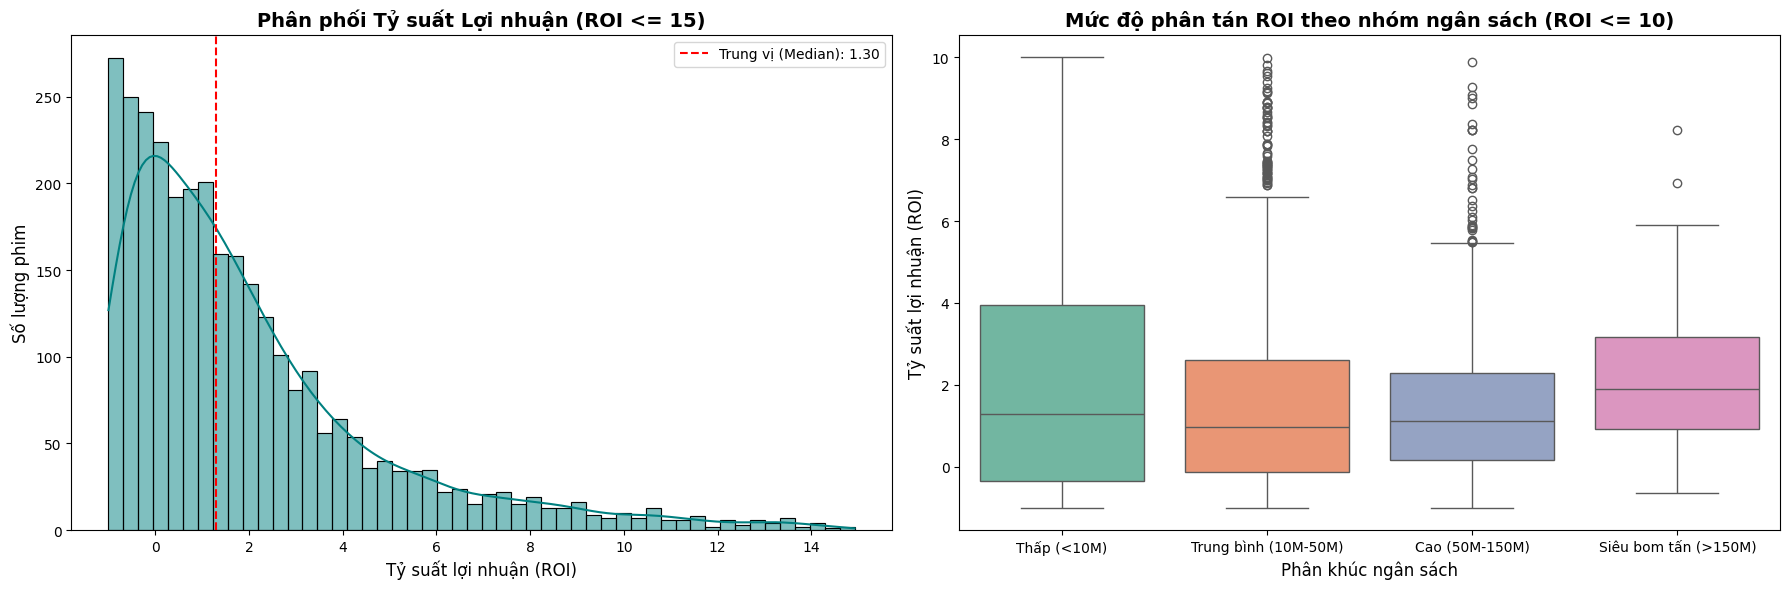

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập kích thước đồ thị
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Biểu đồ 1: Phân phối tổng quan của ROI (Giới hạn ở khoảng ROI từ -1 đến 15 để dễ quan sát)
sns.histplot(
    df_roi[df_roi['ROI'] <= 15]['ROI'],
    kde=True,
    color='teal',
    bins=50,
    ax=axes[0]
)
axes[0].set_title('Phân phối Tỷ suất Lợi nhuận (ROI <= 15)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Tỷ suất lợi nhuận (ROI)', fontsize=12)
axes[0].set_ylabel('Số lượng phim', fontsize=12)
axes[0].axvline(df_roi['ROI'].median(), color='red', linestyle='--', label=f'Trung vị (Median): {df_roi["ROI"].median():.2f}')
axes[0].legend()

# Biểu đồ 2: Phân tán ROI theo từng nhóm Ngân sách bằng Boxplot (Giới hạn ROI <= 10 để tập trung cấu trúc chính)
bins = [0, 10e6, 50e6, 150e6, float('inf')]
labels = ['Thấp (<10M)', 'Trung bình (10M-50M)', 'Cao (50M-150M)', 'Siêu bom tấn (>150M)']
df_roi['budget_group'] = pd.cut(df_roi['budget'], bins=bins, labels=labels)

sns.boxplot(
    x='budget_group',
    y='ROI',
    data=df_roi[df_roi['ROI'] <= 10],
    palette='Set2',
    hue='budget_group',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Mức độ phân tán ROI theo nhóm ngân sách (ROI <= 10)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Phân khúc ngân sách', fontsize=12)
axes[1].set_ylabel('Tỷ suất lợi nhuận (ROI)', fontsize=12)

plt.tight_layout()
plt.show()

### Phân tích Phân phối Tỷ suất Lợi nhuận (ROI Distribution)
Bước này sẽ giúp chúng ta thấy rõ mức độ phân tán của ROI (Lợi nhuận ròng chia cho Ngân sách) nhằm nhận diện đa số các phim có tỷ suất sinh lời nằm ở khoảng nào, và những phim thành công vượt trội (outliers) nằm ở đâu.

In [10]:
import sqlite3
import pandas as pd

def extract(file_path: str) -> pd.DataFrame:
    """1. EXTRACT: Đọc dữ liệu từ file CSV thô."""
    print("[+] Đang đọc dữ liệu thô...")
    df = pd.read_csv(file_path)
    return df

def transform(df: pd.DataFrame) -> pd.DataFrame:
    """2. TRANSFORM: Làm sạch và chuẩn hóa các cột."""
    print("[+] Đang chuẩn hóa dữ liệu...")

    # 2.1 Cột full_name: Loại bỏ khoảng trắng thừa + Viết hoa chữ cái đầu mỗi từ
    df['full_name'] = df['full_name'].astype(str).str.strip().str.title()

    # 2.2 Cột email: Xóa khoảng trắng + Chuyển toàn bộ về chữ thường
    df['email'] = df['email'].astype(str).str.strip().str.lower()

    # 2.3 Cột phone: Xóa ký tự không phải số (khoảng trắng, dấu chấm)
    df['phone'] = df['phone'].astype(str).str.replace(r'\D', '', regex=True)

    return df

def load(df: pd.DataFrame, db_name: str, csv_out: str):
    """3. LOAD: Ghi dữ liệu vào Database SQLite và lưu bản sao CSV."""
    print("[+] Đang ghi dữ liệu vào SQLite và CSV mới...")

    # Ghi vào SQLite Database
    conn = sqlite3.connect(db_name)
    df.to_sql('cleaned_users', conn, if_exists='replace', index=False)
    conn.close()

    # Ghi ra file CSV đã làm sạch
    df.to_csv(csv_out, index=False)
    print("[✔] Đã hoàn thành Pipeline thành công!")

if __name__ == '__main__':
    # Chạy quy trình ETL
    data_raw = extract('/content/drive/MyDrive/input_data.csv')
    data_clean = transform(data_raw)
    load(data_clean, db_name='database.db', csv_out='output_data_cleaned.csv')

[+] Đang đọc dữ liệu thô...
[+] Đang chuẩn hóa dữ liệu...
[+] Đang ghi dữ liệu vào SQLite và CSV mới...
[✔] Đã hoàn thành Pipeline thành công!
